# Topic 4 Lab — Data Quality and Responsible Data Practices
**Project author | ID omitted | SAIA3113 AI Engineering**  
**Review date: 25 November 2026**

Project: **Explainable Student Dropout Prediction Using Early Academic Indicators**.

This notebook continues the Topic 3 student-outcome project, using the same fixed UCI release and two papers. It profiles quality, runs Pandera rules, reviews warnings, preserves duplicate provenance, assesses coverage and governance, and writes the seven required deliverables. It does not train a model or call an LLM.

Run all cells in order. In Colab, the first cell installs the four pinned libraries; the next cell fetches the exact public Lab 3 inputs if they are absent. A changed input hash stops the run. Local student-row data is a working cache and is excluded from the final public/submission package. The final cell offers a ZIP download in Colab.

The saved execution provenance is printed near the end; it distinguishes a local run from a Colab run. Manual review notes refer to the fixed source versions and are not automatically regenerated judgements.

**Public copy:** Student name and matric number have been removed from this notebook, its report text and displayed download filename. The private submission retains those details. The executed validation logic and numeric findings are unchanged.

In [1]:
import importlib.metadata, subprocess, sys, os
from pathlib import Path
required={'pandas':'3.1.1','pandera':'0.36.0','matplotlib':'3.11.2','langchain-core':'1.8.4'}
missing=[]
for name,version in required.items():
    try:
        if importlib.metadata.version(name)!=version: missing.append(f'{name}=={version}')
    except importlib.metadata.PackageNotFoundError:
        missing.append(f'{name}=={version}')
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
os.environ.setdefault('MPLCONFIGDIR',str(Path.cwd()/'.week4_matplotlib'))
print('Pinned dependencies ready:',required)

Pinned dependencies ready: {'pandas': '3.1.1', 'pandera': '0.36.0', 'matplotlib': '3.11.2', 'langchain-core': '1.8.4'}


## Part A — Assess and validate the prepared data
### A0. Plan the gate from Topic 2 requirements

| Requirement | Data required | Dimensions | Observable check | Decision |
|---|---|---|---|---|
| FR2: only eligible T0/T1 features | Documented availability, fixed feature policy | Consistency, accuracy, timeliness | 8/14 allowlists, no target/IDs/future/uncertain snapshot fields | Stop on a forbidden predictor |
| FR5: traceable manual reference guide | Source identity, page locators, readable passages | Completeness, accuracy, consistency, uniqueness | Registry/locator checks, page inspection and duplicate review | Quarantine unreliable extraction; source-check retained text |

The teacher's example expects `prepared_chunks.jsonl` and `chunks.pkl`. Our actual Lab 3 output is `prepared_text.jsonl`. A verified adapter below creates those compatibility names without rewriting any text or original metadata. No missing hand-off is silently assumed.

### Imports and fixed configuration

In [2]:
from pathlib import Path
from collections import Counter, defaultdict
import os, sys, json, re, pickle, hashlib, urllib.request, zipfile, io, platform
from datetime import datetime, timezone
import pandas as pd
import pandera.pandas as pa
import matplotlib.pyplot as plt
from langchain_core.documents import Document
from IPython.display import display, Markdown

ROOT = Path.cwd()
for folder in ['data', 'data/week4_input', 'docs', 'evidence']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
BASE_COMMIT = '808330bf96c995353e46038f960e25e455474842'
BASE_URL = f'https://raw.githubusercontent.com/ykwooga-afk/ai-engineering-labs/{BASE_COMMIT}/'
TEXT_SHA = '568ca0a5296fb30feb291951f84a2321940f2133054217de5e416d3556ec50b3'
TABLE_SHA = '3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae'

def sha(data):
    return hashlib.sha256(data).hexdigest()

def save_json(path, obj):
    (ROOT/path).write_text(json.dumps(obj, ensure_ascii=False, indent=2)+'\n', encoding='utf-8')

def fetch_input(remote, local, expected=None):
    path=ROOT/local
    if not path.exists():
        path.write_bytes(urllib.request.urlopen(BASE_URL+remote, timeout=60).read())
    data=path.read_bytes()
    if expected and sha(data)!=expected:
        raise ValueError(f'Input checksum mismatch: {local}. Stop and investigate the version.')
    return data

raw_text = fetch_input('data/processed/prepared_text.jsonl', 'data/week4_input/prepared_text.jsonl', TEXT_SHA)
registry = json.loads(fetch_input('data/source_registry.json', 'data/week4_input/source_registry.json'))
allowlists = json.loads(fetch_input('data/processed/feature_allowlists.json', 'data/week4_input/feature_allowlists.json'))
original = [json.loads(line) for line in raw_text.decode('utf-8').splitlines() if line.strip()]
assert len(original)==168
print('Pinned Lab 3 commit:',BASE_COMMIT)
print('Verified input SHA-256:',sha(raw_text))
print('Prepared paper chunks:',len(original))

Pinned Lab 3 commit: 808330bf96c995353e46038f960e25e455474842
Verified input SHA-256: 568ca0a5296fb30feb291951f84a2321940f2133054217de5e416d3556ec50b3
Prepared paper chunks: 168


### A1: verified hand-off adapter, with no changes to text or old metadata

In [3]:
records=[]
for i, r in enumerate(original):
    meta={k:v for k,v in r.items() if k!='text'}
    records.append({'chunk_id': i, 'text': r['text'], 'metadata':meta})
chunks=[Document(page_content=r['text'],metadata=r['metadata']) for r in records]
(ROOT/'data/prepared_chunks.jsonl').write_text(''.join(json.dumps(r,ensure_ascii=False)+'\n' for r in records),encoding='utf-8')
with (ROOT/'data/chunks.pkl').open('wb') as f:
    pickle.dump(chunks,f,protocol=4)
# Only load a pickle just generated here from the checksum-verified JSONL.
with (ROOT/'data/chunks.pkl').open('rb') as f:
    loaded=pickle.load(f)
reloaded=[json.loads(x) for x in (ROOT/'data/prepared_chunks.jsonl').read_text(encoding='utf-8').splitlines()]
assert len(loaded)==len(reloaded)==168
assert all(c.page_content==r['text'] and c.metadata==r['metadata'] for c,r in zip(loaded,reloaded))
assert all(r['text']==old['text'] and r['metadata']=={k:v for k,v in old.items() if k!='text'} for r,old in zip(reloaded,original))
print('JSONL / PKL / Lab 3 text and metadata: exact equality verified, 168 records.')
print('Adapter creates the two course hand-off names; they were not claimed to exist in Lab 3.')

JSONL / PKL / Lab 3 text and metadata: exact equality verified, 168 records.
Adapter creates the two course hand-off names; they were not claimed to exist in Lab 3.


### A2: profile the prepared text and project-specific provenance

In [4]:
rows=[]
for r in records:
    m=r['metadata']; t=r['text']; source=registry[m['source_id']]
    rows.append(dict(chunk_id=r['chunk_id'],record_id=m['record_id'],source_id=m['source_id'],
        source=m['source'],page=m['page'],text=t,char_count=len(t.strip()),
        missing_text=not bool(t.strip()),missing_source=not bool(m.get('source','').strip()),
        corrupted_char=('\x00' in t or '\ufffd' in t),
        noisy_whitespace=bool(re.search(r'\n{4,}| {4,}',t)),
        provenance_ok=(m.get('source_sha256')==source['sha256'] and m.get('source_url')==source['url']
                       and m.get('source_version')==source['version'] and m.get('licence')==source['licence']),
        page_ok=(isinstance(m.get('page'),int) and 1<=m['page']<={'S02':17,'S03':15}[m['source_id']]),
        span_ok=(m['end_char_in_clean_page']-m['start_char_in_clean_page']==len(t)),
        short_chunk=len(t.strip())<100,
        extraction_risk='peer_review_text_in_extraction' in m['warnings'],
        dense_page='unusually_dense_extraction' in m['warnings'],
        table_order_risk='possible_table_reading_order_loss' in m['warnings'],
        publisher_sidebar='publisher_sidebar_retained' in m['warnings']))
df=pd.DataFrame(rows)
profile={key:int(df[key].sum()) for key in ['missing_text','missing_source','corrupted_char','noisy_whitespace','short_chunk','extraction_risk','dense_page','table_order_risk','publisher_sidebar']}
print(json.dumps(profile,indent=2))
display(df[['char_count']].describe())
save_json('evidence/week4_profile.json',profile)

{
  "missing_text": 0,
  "missing_source": 0,
  "corrupted_char": 0,
  "noisy_whitespace": 0,
  "short_chunk": 2,
  "extraction_risk": 78,
  "dense_page": 55,
  "table_order_risk": 104,
  "publisher_sidebar": 10
}


,char_count
count,168.000000
mean,867.839286
std,200.672860
min,91.000000
25%,900.500000
50%,942.500000
75%,973.000000
max,999.000000


### A3: deterministic inspection sample, with original page locators

In [5]:
sample=df.sample(n=10,random_state=42)
for row in sample.itertuples():
    print(f'\nCHUNK {row.chunk_id} | {row.record_id} | page {row.page}\n{row.text}')
sample[['chunk_id','record_id','source_id','page','char_count']].to_csv(ROOT/'docs/week4_manual_sample.csv',index=False)


CHUNK 137 | S03-2f092cb9803c-p007-c001901 | page 7
Several dedicated Python libraries were used to develop this work, namely,pandas [34]
for data analysis and data wrangling, seaborn [35] for data visualization, scikit-learn [36] for
general machine learning tasks, and the imbalanced-learn [37] module for data balancing
algorithms. All the computations ran on the Ubuntu operating system on an NVIDIA
DGX Station computer with 2 CPU Intel Xeon E5-2698V4 with 20 core 2.2 GHz, 256 GB of
memory, and 4 NVIDIA Tesla V100 GPU.
5. Results and Discussion
The global evaluation metrics for each model and for each dataset are presented in
Table 3 (dataset at the time of enrollment, S0), Table 4 (dataset at the end of the first semester,
S1), and Table 5 (dataset at the end of the second semester, S2). The metrics presented are
the global F1 score for the train and test sets and also the balanced accuracy for the test set.
Globally, there is a significant improvement on the models from S0, where th

### A3 observations and reflection

The sample is chunks 137, 30, 119, 29, 142, 161, 164, 51, 105 and 60. On S02 page 5, chunk 29 repeats a paragraph and mixes it with table content; on page 6, chunk 51 crosses table/page relationships. The rendered originals show orderly tables that do not match this extracted sequence. These are accuracy and consistency defects, not simply long passages.

S03 chunk 142 is only 91 characters, but the original page 8 ends at that exact line and page 9 continues the sentence. It is a valid short exception that requires adjacent-page context. Several sampled passages are bibliography entries: their existence does not support an arbitrary project claim.

Reflection: a wrong relationship between readable table values is difficult to detect with a numeric or character rule. Manual comparison reveals meaning that the length and Unicode tests miss. Short text alone is also insufficient grounds for deletion.

### A4: Pandera rules collect all failures, including review warnings

In [6]:
# Each boolean records a different observable condition. False positive risks are
# handled by the decision column; warning failures never silently delete text.
rule_specs=[
 ('R1','missing_text',False,'Hard fail','Nonblank text','Empty evidence cannot support FR5.'),
 ('R2','missing_source',False,'Hard fail','Nonblank source','A passage must be traceable.'),
 ('R3','corrupted_char',False,'Quarantine','No NUL or U+FFFD','These characters indicate damaged extraction, not all possible corruption.'),
 ('R4','provenance_ok',True,'Hard fail','Hash, URL, version and licence equal source registry','Prevents source/version drift.'),
 ('R5','page_ok',True,'Hard fail','Page in source-specific range: S02 1–17; S03 1–15','Supports page-level verification.'),
 ('R6','span_ok',True,'Hard fail','Original end minus start equals original text length','Protects inherited source offsets.'),
 ('R7','short_chunk',False,'Review','At least 100 characters','A screening threshold for boundary fragments; not proof that short text is wrong.'),
 ('R8','extraction_risk',False,'Quarantine pending re-extraction','No inherited peer-review extraction warning','Known affected pages have unreliable reading order; apply a conservative page-level hold.'),
 ('R9','table_order_risk',False,'Review','No inherited table reading-order warning','Linear text can lose table relationships even when valid Unicode.'),
 ('R10','publisher_sidebar',False,'Review','No inherited publisher sidebar warning','Front matter can displace task-relevant evidence.'),
 ('R11','noisy_whitespace',False,'Review','No run of four spaces or four newlines','Detects gross whitespace noise only.'),
 ('R12','dense_page',False,'Review','No inherited dense-extraction warning','Unusual page volume is a warning, not an independent deletion rule.')]
schema=pa.DataFrameSchema({col:pa.Column(bool,checks=pa.Check.eq(expected,name=rid)) for rid,col,expected,*_ in rule_specs},strict=False)
try:
    schema.validate(df,lazy=True)
    pandera_failures=pd.DataFrame(columns=['schema_context','column','check','check_number','failure_case','index'])
except pa.errors.SchemaErrors as exc:
    pandera_failures=exc.failure_cases.copy()
pandera_failures.to_csv(ROOT/'docs/week4_pandera_failure_cases.csv',index=False)
failures=[]; rule_summary=[]
for rid,col,expected,action,condition,reason in rule_specs:
    bad=df[df[col]!=expected]
    rule_summary.append(dict(rule=rid,field=col,condition=condition,failures=len(bad),percent=round(len(bad)/len(df)*100,2),action=action,reason=reason))
    for r in bad.itertuples():
        failures.append(dict(rule=rid,chunk_id=r.chunk_id,record_id=r.record_id,source_id=r.source_id,page=r.page,
                             condition=condition,action=action,observed=str(getattr(r,col))))
assert len(pandera_failures)==len(failures), 'Pandera and explicit rule accounting disagree'
validation=pd.DataFrame(failures,columns=['rule','chunk_id','record_id','source_id','page','condition','action','observed'])
validation.to_csv(ROOT/'docs/week4_validation_failures.csv',index=False)
pd.DataFrame(rule_summary).to_csv(ROOT/'docs/week4_rule_summary.csv',index=False)
display(pd.DataFrame(rule_summary)[['rule','field','failures','percent','action']])
print('Rule failures / warnings:',len(validation),'on',validation.chunk_id.nunique(),'distinct chunks; multiple flags may overlap.')
hard=[s['field'] for s in rule_summary if s['action']=='Hard fail' and s['failures']]
assert not hard, f'Unresolved hard failures: {hard}'

,rule,field,failures,percent,action
0,R1,missing_text,0,0.00,Hard fail
1,R2,missing_source,0,0.00,Hard fail
2,R3,corrupted_char,0,0.00,Quarantine
3,R4,provenance_ok,0,0.00,Hard fail
4,R5,page_ok,0,0.00,Hard fail
5,R6,span_ok,0,0.00,Hard fail
6,R7,short_chunk,2,1.19,Review
7,R8,extraction_risk,78,46.43,Quarantine pending re-extraction
8,R9,table_order_risk,104,61.90,Review
9,R10,publisher_sidebar,10,5.95,Review


Rule failures / warnings: 249 on 127 distinct chunks; multiple flags may overlap.


### A5. Triage of at least three flagged cases

Three targeted triage decisions are recorded below; chunk numbers refer to the original zero-based input order, not newly renumbered records.

| Item / rule | Evidence checked | Interpretation | Decision and reason |
|---|---|---|---|
| Chunk 29, S02 page 5; R8/R9/R12 | The rendered page contains Tables 2–4. The extracted chunk includes a preceding analysis paragraph and its text occurs six times across chunks 21, 24, 27, 29, 32 and 35. | Actual extraction defect: repetition and displaced page content. | Quarantine the affected page's chunks rather than select an arbitrary copy as authoritative. |
| Chunk 51, S02 page 6; R8/R9/R12 | The original page contains Tables 5–8 in order. The chunk mixes first-semester values with tuition-fee and macroeconomic material from the previous page. | Actual extraction defect: row relationships and page order are unreliable. | Quarantine; consult the rendered PDF directly until a separate re-extraction is verified. |
| Chunk 142, S03 page 8; R7/R9 | The 91-character fragment matches the final line of page 8. Its sentence continues at the top of page 9. | Valid short exception, but not a self-contained statement. | Retain unchanged with `boundary_context_required=true`; require adjacent-page checking before use. |



### B1: exact duplicate review across ALL inputs; preserve all source occurrences

In [7]:
def norm(t):
    return re.sub(r'\s+',' ',t.strip())
groups=defaultdict(list)
for r in records:
    groups[sha(norm(r['text']).encode('utf-8'))].append(r)
dup_rows=[]
for digest,items in groups.items():
    first=items[0]
    for extra in items[1:]:
        dup_rows.append(dict(normalized_sha256=digest,first_record_id=first['metadata']['record_id'],
            duplicate_record_id=extra['metadata']['record_id'],source_id=extra['metadata']['source_id'],
            page=extra['metadata']['page'],decision='Preserve all provenance; affected extraction page remains quarantined'))
duplicates=pd.DataFrame(dup_rows,columns=['normalized_sha256','first_record_id','duplicate_record_id','source_id','page','decision'])
duplicates.to_csv(ROOT/'docs/week4_duplicate_review.csv',index=False)
clean=[]; quarantine=[]
for digest,items in groups.items():
    allowed=[r for r in items if not df.loc[r['chunk_id'],'extraction_risk'] and not df.loc[r['chunk_id'],'corrupted_char']]
    provenance=[r['metadata'].copy() for r in items]
    for r in items:
        if r not in allowed:
            m=dict(r['metadata'],week4_status='quarantined_extraction',week4_reason='Conservative hold on inherited unreliable extraction page; original PDF is still available.',
                   normalized_text_sha256=digest,all_provenance=provenance)
            quarantine.append(dict(chunk_id=r['chunk_id'],text=r['text'],metadata=m))
    if allowed:
        r=allowed[0]
        m=dict(r['metadata'],week4_status='retained_for_manual_reference',week4_review_date='2026-11-25',
               week4_text_changed=False,normalized_text_sha256=digest,all_provenance=provenance,
               approved_for_automatic_retrieval=False,requires_source_check_before_claim=True,
               boundary_context_required=bool(df.loc[r['chunk_id'],'short_chunk']))
        clean.append(dict(chunk_id=r['chunk_id'],text=r['text'],metadata=m))
clean.sort(key=lambda r:r['chunk_id']);quarantine.sort(key=lambda r:r['chunk_id'])
for name,values in [('prepared_chunks_clean.jsonl',clean),('prepared_chunks_quarantine.jsonl',quarantine)]:
    (ROOT/'data'/name).write_text(''.join(json.dumps(r,ensure_ascii=False)+'\n' for r in values),encoding='utf-8')
with (ROOT/'data/chunks_clean.pkl').open('wb') as f:
    pickle.dump([Document(page_content=r['text'],metadata=r['metadata']) for r in clean],f,protocol=4)
print(f'Input {len(records)}; exact duplicate extras {len(duplicates)} in {sum(len(v)>1 for v in groups.values())} groups.')
print(f'Retained {len(clean)}; quarantined {len(quarantine)}. Duplicate groups overlap quarantine and must not be subtracted twice.')
print('No source text rewritten. Original chunk IDs, offsets, warnings and all duplicate provenance retained.')

Input 168; exact duplicate extras 9 in 4 groups.


Retained 90; quarantined 78. Duplicate groups overlap quarantine and must not be subtracted twice.
No source text rewritten. Original chunk IDs, offsets, warnings and all duplicate provenance retained.


## Part B — Duplicates, coverage and responsible data
### Scope-led coverage plan (defined before source counts)

The benchmark needs dataset/outcome definitions, documented enrolment and semester-one feature meanings, phased-prediction interpretation, and subgroup-support evidence. Equal paper lengths or equal chunk counts are not required. Detailed feature definitions need original source tables, the prediction study supports phase interpretation, and the table supplies recorded classes and audit groups. No current UTM policy or student cohort is in scope. Quarantine may create a coverage gap even when many other chunks remain.

### B2: source coverage after a scope-led coverage plan

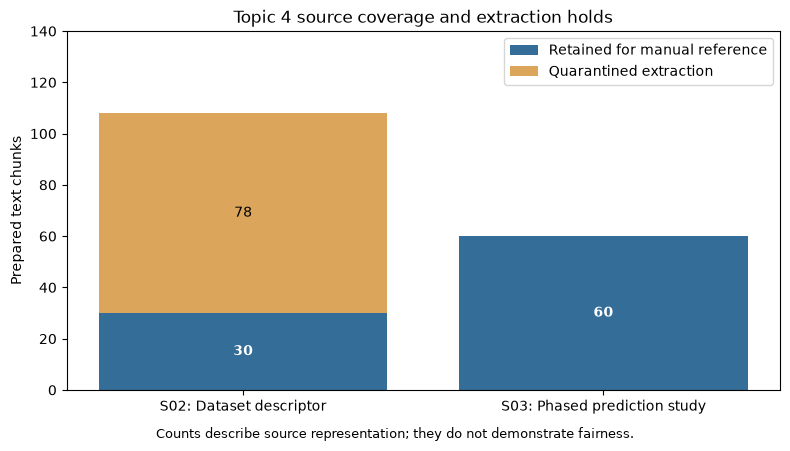

,source_id,role,input_chunks,retained_chunks,quarantined_chunks,retained_percent
0,S02,Dataset descriptor,108,30,78,33.33
1,S03,Phased prediction study,60,60,0,66.67


In [8]:
before=Counter(r['metadata']['source_id'] for r in records)
after=Counter(r['metadata']['source_id'] for r in clean)
coverage=pd.DataFrame([dict(source_id=s,role={'S02':'Dataset descriptor','S03':'Phased prediction study'}[s],input_chunks=before[s],retained_chunks=after[s],quarantined_chunks=before[s]-after[s],retained_percent=round(after[s]/len(clean)*100,2)) for s in sorted(before)])
coverage.to_csv(ROOT/'docs/week4_coverage_by_source.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4.5))
x=list(range(len(coverage)))
ax.bar(x,coverage.retained_chunks,label='Retained for manual reference',color='#356d99')
ax.bar(x,coverage.quarantined_chunks,bottom=coverage.retained_chunks,label='Quarantined extraction',color='#dba55b')
ax.set_xticks(x,[f'{r.source_id}: {r.role}' for r in coverage.itertuples()])
ax.set_ylabel('Prepared text chunks');ax.set_title('Topic 4 source coverage and extraction holds')
for i,r in enumerate(coverage.itertuples()):
    ax.text(i,r.retained_chunks/2,str(r.retained_chunks),ha='center',va='center',color='white',fontweight='bold')
    if r.quarantined_chunks: ax.text(i,r.retained_chunks+r.quarantined_chunks/2,str(r.quarantined_chunks),ha='center',va='center')
ax.legend(loc='upper right');ax.set_ylim(0,140)
fig.text(.5,.015,'Counts describe source representation; they do not demonstrate fairness.',ha='center',fontsize=9)
fig.tight_layout(rect=(0,.035,1,1));fig.savefig(ROOT/'docs/week4_coverage_by_source.png',dpi=160)
display(fig);plt.close(fig)
display(coverage)

### Supplement: verify the predictive table and aggregate domain coverage, without publishing rows

In [9]:
table_file=ROOT/'data/week4_input/uci_dropout.csv'
if not table_file.exists():
    archive=urllib.request.urlopen(registry['S01']['download_url'],timeout=90).read()
    with zipfile.ZipFile(io.BytesIO(archive)) as z:
        table_file.write_bytes(z.read('data.csv'))
assert sha(table_file.read_bytes())==TABLE_SHA,'UCI source version changed; do not silently update the project'
table=pd.read_csv(table_file,sep=';');table.columns=table.columns.str.strip()
assert table.shape==(4424,37)
forbidden={'Target','row_id','Gender','Nacionality','Debtor','Tuition fees up to date','Scholarship holder','Unemployment rate','Inflation rate','GDP'}
for point in ['T0','T1']:
    assert not (set(allowlists[point])&forbidden)
    assert not any('2nd sem' in c for c in allowlists[point])
    assert set(allowlists[point]).issubset(table.columns)
assert len(allowlists['T0'])==8 and len(allowlists['T1'])==14
assert not any('1st sem' in c for c in allowlists['T0'])
features=table.drop(columns='Target')
conflicts=features.duplicated(keep=False)
table_profile=dict(rows=len(table),columns=len(table.columns),missing_cells=int(table.isna().sum().sum()),
                   exact_duplicate_rows=int(table.duplicated().sum()),duplicate_predictor_profiles=int(conflicts.sum()),
                   target_counts={str(k):int(v) for k,v in table.Target.value_counts().items()},
                   T0_predictors=8,T1_predictors=14,
                   non_portuguese_records=int((table.Nacionality!=1).sum()),
                   unknown_parent_qualification_codes=int(((table["Mother's qualification"].isin([34])) | (table["Father's qualification"].isin([34]))).sum()))
assert set(table.Target)=={'Dropout','Enrolled','Graduate'}
assert table_profile['missing_cells']==0
assert table_profile['exact_duplicate_rows']==0
assert table_profile['duplicate_predictor_profiles']==0
assert table['Previous qualification (grade)'].between(0,200).all()
assert table['Admission grade'].between(0,200).all()
assert table['Curricular units 1st sem (grade)'].between(0,20).all()
assert (table['Curricular units 1st sem (approved)']<=table['Curricular units 1st sem (enrolled)']).all()
domain=[]
for kind,values in [('Recorded gender',table.Gender.map({0:'0: female',1:'1: male'})),('Age at enrolment',table['Age at enrollment'].map(lambda x:'Under 25' if x<25 else '25 or older'))]:
    assert values.notna().all()
    for group in sorted(values.unique()):
        subset=table.loc[values==group,'Target'];d=int((subset=='Dropout').sum())
        domain.append(dict(grouping=kind,group=group,records=len(subset),dropout=d,non_dropout=len(subset)-d,percent=round(len(subset)/len(table)*100,2)))
domain=pd.DataFrame(domain)
domain.to_csv(ROOT/'docs/week4_domain_coverage.csv',index=False)
save_json('evidence/week4_table_profile.json',table_profile)
print(json.dumps(table_profile,indent=2));display(domain)
print('These are full-corpus support counts, not test-set eligibility or measured fairness.')

{
  "rows": 4424,
  "columns": 37,
  "missing_cells": 0,
  "exact_duplicate_rows": 0,
  "duplicate_predictor_profiles": 0,
  "target_counts": {
    "Graduate": 2209,
    "Dropout": 1421,
    "Enrolled": 794
  },
  "T0_predictors": 8,
  "T1_predictors": 14,
  "non_portuguese_records": 110,
  "unknown_parent_qualification_codes": 142
}


,grouping,group,records,dropout,non_dropout,percent
0,Recorded gender,0: female,2868,720,2148,64.83
1,Recorded gender,1: male,1556,701,855,35.17
2,Age at enrolment,25 or older,1138,631,507,25.72
3,Age at enrolment,Under 25,3286,790,2496,74.28


These are full-corpus support counts, not test-set eligibility or measured fairness.


### C2: full reload verification and execution provenance

In [10]:
with (ROOT/'data/chunks_clean.pkl').open('rb') as f:
    check_pickle=pickle.load(f)
check_json=[json.loads(x) for x in (ROOT/'data/prepared_chunks_clean.jsonl').read_text(encoding='utf-8').splitlines()]
assert len(check_pickle)==len(check_json)==90
assert len(quarantine)==78 and len(duplicates)==9
assert all(c.page_content==r['text'] and c.metadata==r['metadata'] for c,r in zip(check_pickle,check_json))
assert len({sha(norm(c.page_content).encode()) for c in check_pickle})==len(check_pickle)
assert all(r['text']==records[r['chunk_id']]['text'] for r in check_json)
assert not set(r['chunk_id'] for r in check_json)&set(r['chunk_id'] for r in quarantine)
assert set(r['chunk_id'] for r in check_json)|set(r['chunk_id'] for r in quarantine)==set(range(168))
import importlib.metadata
execution=dict(executed_utc=datetime.now(timezone.utc).isoformat(),platform=platform.platform(),python=platform.python_version(),
               runtime='Google Colab' if 'google.colab' in sys.modules else 'Local Python',
               versions={name:importlib.metadata.version(name) for name in ['pandas','pandera','matplotlib','langchain-core']},
               input_commit=BASE_COMMIT,input_text_sha256=TEXT_SHA,input_table_sha256=TABLE_SHA,
               input_chunks=len(records),clean_chunks=len(clean),quarantined_chunks=len(quarantine),duplicate_extras=len(duplicates),
               jsonl_pickle_text_and_metadata_equal=True,source_text_preserved=True,model_calls=0,
               quality_gate='GO WITH CONDITIONS',fairness_evaluated=False)
save_json('evidence/week4_execution.json',execution)
print(json.dumps(execution,indent=2))

{
  "executed_utc": "2026-11-25T15:12:34.053535+00:00",
  "platform": "Windows-11-10.0.26200-SP0",
  "python": "3.12.14",
  "runtime": "Local Python",
  "versions": {
    "pandas": "3.1.1",
    "pandera": "0.36.0",
    "matplotlib": "3.11.2",
    "langchain-core": "1.8.4"
  },
  "input_commit": "808330bf96c995353e46038f960e25e455474842",
  "input_text_sha256": "568ca0a5296fb30feb291951f84a2321940f2133054217de5e416d3556ec50b3",
  "input_table_sha256": "3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae",
  "input_chunks": 168,
  "clean_chunks": 90,
  "quarantined_chunks": 78,
  "duplicate_extras": 9,
  "jsonl_pickle_text_and_metadata_equal": true,
  "source_text_preserved": true,
  "model_calls": 0,
  "quality_gate": "GO WITH CONDITIONS",
  "fairness_evaluated": false
}


### B3/B4. Bias and governance interpretation

The following report records three risks with evidence: source-population/class representation, outcome/timestamp measurement, and distortion caused by extraction and quarantine. Each follows source → transformation → prepared evidence → possible later retrieval opportunity → user-facing consequence. The current project uses a classifier and manual reference guide, so any future RAG consequence is explicitly conditional.

Public sources have CC BY attribution requirements. No consent record is inferred from public access. Student rows stay out of the public package, and no model receives them. Source versions, limits, ownership and retention actions are documented in the eight-section report below. Full-dataset group counts are not measured model fairness.

## Part C — Consolidated eight-section report and output verification

In [11]:
REPORT_TEMPLATE = "# Data Quality, Bias, and Responsible Data Report — Explainable Student Dropout Prediction Using Early Academic Indicators\n\n**Name:** Project author  \n**Matric number:** ID omitted  \n**Course:** SAIA3113 AI Engineering — Topic 4 Lab  \n**Review date:** 25 November 2026\n\nThis report continues the same project from Topics 1–3. The main task is an offline, three-class comparison of enrolment (T0) and end-of-first-semester (T1) predictors. The papers support a manually checked reference guide. They are not training labels, and this project has not implemented a chatbot or RAG system.\n\nThe input is pinned to Lab 3 commit `808330bf96c995353e46038f960e25e455474842`. Our actual Lab 3 text file was `data/processed/prepared_text.jsonl`. The notebook explicitly creates the course hand-off names `prepared_chunks.jsonl` and `chunks.pkl`, then verifies all 168 texts and metadata dictionaries match the original. This is a format adapter, not a claim that those names were already present. The UCI table is separately checked against its Lab 3 SHA-256. No model training, embeddings, retrieval or model API calls are performed.\n\n## 1. Data Quality Scorecard\n\nThe ratings are engineering judgements within this project's scope: 1 = critical uncontrolled gap; 2 = substantial unresolved gap; 3 = material gap contained by restrictions; 4 = scoped checks pass with documented limits; 5 = complete evidence for the declared scope. N.V. means the dimension cannot be established from the checks performed. Ratings are not percentages or model scores.\n\n| Dimension | Rating (1–5 / N.V.) | Evidence | Action / limitation |\n|---|---:|---|---|\n| Completeness | 3 | 168/168 chunks contain text and source metadata; the table has 4,424 rows and no null cells. However, 78 paper chunks are held, reducing available feature-definition evidence. | Use original source pages for definitions. Do not equate populated fields with complete meaning or coverage. |\n| Consistency | 4 | Source hash, URL, version, licence, page range and character-span checks pass. JSONL and PKL contents agree. T0 has 8 predictors and T1 has 14, with the same exclusions as Topic 3. | Keep the UCI 4,424-row release distinct from the 4,433-record study described in S03, page 4. The cause of that difference remains N.V. |\n| Accuracy | N.V. | Source-page inspection confirms repeated and displaced text in S02 extraction. S03 page 8 has a legitimate sentence continuing onto page 9. Only a sample and targeted cases were examined. | Quarantine affected S02 pages. Verify every substantive future guide claim against the PDF; no full-corpus factual-accuracy claim. |\n| Timeliness | N.V. | Source versions and access dates are recorded. S02 was published in 2022 and S03 in 2023; S03 describes a historical institutional cohort. No current Malaysian cohort is supplied. | These versions are usable for a fixed benchmark exercise. Current cohort relevance and deployment-time snapshot validity are not established. |\n| Uniqueness | 4 | Normalised-text hashing finds 9 duplicate extras in 4 groups; all occur inside the 78 quarantined records. The 90 retained texts have 90 distinct hashes. No exact duplicate table rows or predictor profiles were found. | Exact hashing does not find paraphrases, near-duplicates, conflicting versions or distinct people with similar profiles. |\n\nThe quality gate was planned around these two Topic 2 requirements before choosing rules:\n\n| Requirement | Required data / dimensions | Observable check | Decision |\n|---|---|---|---|\n| FR2: use only justified features at T0 and T1 | Consistency, accuracy and timeliness of feature definitions and availability | Match 8/14-column allowlists; exclude Target, row keys, semester-two fields, audit-only and uncertain snapshot fields | Stop on forbidden fields; retain uncertain fields outside predictors |\n| FR5: provide a traceable, manually checked reference guide | Completeness, accuracy, consistency and uniqueness of source evidence | Check source identity and locators; inspect pages, short fragments and duplicates | Quarantine unreliable extraction; retain other text only for source-checked manual use |\n\n## 2. Validation and Data-Defect Findings\n\nTwelve rules were actually run with Pandera using lazy validation. The table below uses the **168 input chunks** as its denominator. There are **249 rule flags on 127 distinct chunks**; the flags overlap and must not be added as separate defective records. The detailed evidence is in `week4_validation_failures.csv`, and the original Pandera output is in `week4_pandera_failure_cases.csv`.\n\n{{RULE_TABLE}}\n\nThe 100-character threshold is a warning to inspect fragments. It is not a requirement that all meaningful passages exceed 100 characters. Page ranges come from the two actual PDFs. The source-specific warning rules reuse metadata captured in Topic 3 rather than inventing new source classifications.\n\n| Issue category | Observed evidence | Interpretation and action |\n|---|---|---|\n| Missing | 0 blank texts, 0 missing source paths; 0 table null cells | Structural completeness passes. Separately, 142 rows have an explicit unknown code in at least one parent's qualification; no-null does not mean all information is known. These fields are already excluded from predictors. |\n| Corrupted | 0 NUL or replacement-character cases | This narrow character test passes. It does not catch damaged table relationships or repeated text. |\n| Noisy | 0 gross-whitespace flags; 10 publisher-sidebar flags; 55 dense-extraction flags | Formatting checks alone miss irrelevant front matter and duplicated content. Keep flags visible. |\n| Inconsistent | 0 provenance, page-range or span failures; 104 table-order warnings | Metadata consistency passes. Reading order remains a review concern, not a proven error in every flagged chunk. |\n| Duplicated | 9 extra occurrences in 4 exact-text groups | Preserve each occurrence's provenance. All groups are covered by extraction quarantine. |\n| Stale | No record is labelled stale solely because it is old | The sources are fixed historical evidence. Present-day applicability is N.V.; age alone cannot decide fitness for a retrospective benchmark. |\n| Uncertain | 78 inherited extraction-risk flags, incomplete semantic review, uncertain snapshot fields | Hold affected text pages; preserve the existing feature exclusions and source-check requirement. |\n\nThe deterministic sample used `random_state=42`: chunks 137, 30, 119, 29, 142, 161, 164, 51, 105 and 60. The notebook prints their full text and source locators. Bibliography chunks are legitimate source material but are not, by themselves, evidence for a substantive project claim. This is another limitation a simple length check would miss.\n\nThree targeted triage decisions are recorded below; chunk numbers refer to the original zero-based input order, not newly renumbered records.\n\n| Item / rule | Evidence checked | Interpretation | Decision and reason |\n|---|---|---|---|\n| Chunk 29, S02 page 5; R8/R9/R12 | The rendered page contains Tables 2–4. The extracted chunk includes a preceding analysis paragraph and its text occurs six times across chunks 21, 24, 27, 29, 32 and 35. | Actual extraction defect: repetition and displaced page content. | Quarantine the affected page's chunks rather than select an arbitrary copy as authoritative. |\n| Chunk 51, S02 page 6; R8/R9/R12 | The original page contains Tables 5–8 in order. The chunk mixes first-semester values with tuition-fee and macroeconomic material from the previous page. | Actual extraction defect: row relationships and page order are unreliable. | Quarantine; consult the rendered PDF directly until a separate re-extraction is verified. |\n| Chunk 142, S03 page 8; R7/R9 | The 91-character fragment matches the final line of page 8. Its sentence continues at the top of page 9. | Valid short exception, but not a self-contained statement. | Retain unchanged with `boundary_context_required=true`; require adjacent-page checking before use. |\n\n**Manual-inspection reflection:** Valid words and numbers can appear in the wrong table row or page. A Unicode or length rule will pass this text because the symbols themselves are readable. Comparing the extracted passage with the visible table reveals the loss of meaning. Conversely, a short fragment can be valid when a sentence crosses a page boundary. These findings concern accuracy, consistency and completeness of context.\n\n## 3. Duplicate and Anomaly Findings\n\nWhitespace is normalised only for hashing: leading/trailing whitespace is removed and internal whitespace runs become one space. Stored source text is not rewritten. The duplicate groups have sizes 6, 3, 2 and 2, giving 9 extra occurrences. All source metadata dictionaries are retained in `all_provenance`, including source ID, SHA-256, URL, page and original offsets. `week4_duplicate_review.csv` identifies every extra occurrence and its decision.\n\nThe conservative hold covers all chunks on S02 pages 4, 5, 6, 7, 8, 9 and 11 because Topic 3 recorded extraction contamination for those pages. The targeted visual inspection confirms problems on pages 5 and 6; it does **not** prove that every passage on the other flagged pages is wrong. Holding the full affected page set prevents unverified passages from passing simply because a specific duplicate was removed. It may temporarily exclude valid material; that loss is visible in the coverage plot.\n\n**Accounting:** 168 original chunks = 90 retained + 78 quarantined. The 9 duplicate extras are already among the 78, so they are not subtracted again. Both 91-character chunks are flagged: S02 chunk 84 is held with its affected page, while S03 chunk 142 is retained with a context restriction. The quarantine file preserves the original text for repair and audit.\n\nThe clean JSONL and PKL are reloaded and compared for text and metadata equality. Their 90 records have distinct normalised hashes. All inherited warnings remain attached; `week4_status` describes the new disposition without overwriting Topic 3's status. `approved_for_automatic_retrieval=false` is present on every retained record. The clean file is a controlled manual-reference corpus, not blanket approval for automated answers.\n\nS03 page 4 reports 4,433 study records, while the pinned UCI release contains 4,424. I keep both statements tied to their own versions instead of editing one to match the other. Neither exact hashing nor matching file counts resolves that difference. The table's value-range and approved-versus-enrolled checks pass, but they do not establish that original records contain no measurement errors.\n\n## 4. Representation, Coverage, and Bias Assessment\n\nAdequate coverage is defined by the required tasks, not equal numbers of chunks:\n\n| Required area | Expected authoritative evidence | Actual evidence | Gap / decision |\n|---|---|---|---|\n| Dataset and outcome definitions | UCI release documentation and its descriptor | S01 has 4,424 rows; S02 describes the dataset; S03 page 4 defines its study outcomes | Supported for a benchmark, subject to the documented release difference |\n| T0/T1 feature timing | Source definitions separating enrolment and first-semester attributes | Existing Topic 3 allowlists; source tables distinguish the timepoints | Detailed descriptor extraction is partly quarantined. Use the original tables and keep ambiguous fields excluded |\n| Phased prediction interpretation | A cited study describing prediction phases and limitations | S03 provides 60 retained chunks | Study results are context, not our measured results or proof of causal benefit |\n| Subgroup audit feasibility | Recorded group variables and sufficient later test denominators | Aggregate gender and age counts below | Full-dataset support cannot guarantee test-set support; no fairness score yet |\n| UTM deployment / current student advice | Local authorised data and current institutional validation | None supplied | Outside V1 scope. Do not make these claims |\n\n{{COVERAGE_TABLE}}\n\n![Source coverage and extraction holds](week4_coverage_by_source.png)\n\nOriginally S02 contributes 108/168 chunks (64.29%) and S03 contributes 60/168 (35.71%). After quarantine, S02 contributes 30/90 (33.33%) and S03 contributes 60/90 (66.67%). These are different document roles and lengths. The change reflects an extraction intervention; it is not a demographic fairness result.\n\nThe least secure **in-scope** area is faithful, readily reusable feature-definition text because much of the descriptor is held. More prediction-study chunks would not repair that gap. Current Malaysian applicability is an additional evidence absence, but is outside the declared benchmark scope.\n\nThe predictive labels are Graduate 2,209 (49.93%), Dropout 1,421 (32.12%) and Enrolled 794 (17.95%). The domain grouping below uses recorded gender and the age bands already specified in Topic 2, without inferring new identity attributes.\n\n{{DOMAIN_TABLE}}\n\nOnly 110 records have a nationality code other than Portuguese; this is a recorded-code count, not a claim about ethnicity or nationality identity beyond the supplied field. The gender coding is limited to the source's two categories. Neither this count nor excluding gender from predictors demonstrates fairness.\n\n| Risk / origin / affected group | Propagation path | Intervention and Topic 8 follow-up |\n|---|---|---|\n| Historical and representation risk: one Portuguese institutional setting; the paper describes a historical cohort, and Enrolled is the smallest target class. Students outside that setting and smaller classes may be poorly represented. | Source population and selection → imbalanced prepared table and narrow reference evidence → in V1, model fitting and manual evidence selection favour what is available → potentially uneven errors or overgeneralised explanations. If retrieval is added later, the same narrow source set limits what can be retrieved and generated. | Keep the benchmark-only scope; stratify the future split; fit any balancing inside training folds only. Topic 8 must report per-class metrics, group error gaps and uncertainty. External transfer remains untested without suitable new data. |\n| Measurement risk: final recorded outcome is a proxy for academic status, not an observed reason for leaving or a semester-one dropout date. Several financial/status timestamps are uncertain. | Institutional definitions and snapshots → labels/feature windows → in V1, learned estimates and guide interpretations → a user could mistake association for cause or retrospective performance for prospective capability. A future retriever could repeat the same misleading interpretation. | Keep three classes and the fixed timing exclusions; state the outcome horizon. Topic 8 tests forbidden fields, disclosure correctness and explanations. It cannot infer causal intervention benefit from this benchmark. |\n| Pipeline-induced representation risk: extraction noise inflates S02's count, while a broad quarantine reduces descriptor access. | PDF text layer → duplicated/misordered chunks, followed by a source-skewed retained corpus → later retrieval could over-weight repeated text before cleaning or miss definitions after cleaning → inaccurate or incomplete answers. | Preserve quarantine and lineage; use original pages for manual claims. Before any Topic 7 index, verify claim-level evidence and repair affected text. If a RAG extension is approved, Topic 8 needs source/definition coverage, retrieval recall and citation checks; none is claimed here. |\n\n**Bias reflection:** The first risk originates mainly in the source population; the third is introduced or amplified by extraction and filtering. Both can change the evidence the system sees, but counts alone cannot show whether a final user is treated unfairly. The controls interrupt different points of the chain. System behaviour still requires later evaluation.\n\n## 5. Privacy, Consent, Rights/Access, and Data Governance\n\n| Source | Owner / version / provenance | Rights and access | Collection basis and limitation |\n|---|---|---|---|\n| S01: UCI Predict Students' Dropout and Academic Success | Realinho, Vieira Martins, Machado and Baptista; UCI public release retrieved 12 November 2026; full SHA-256 retained in the notebook and registry | UCI lists CC BY 4.0. Reuse needs attribution; public availability is not public-domain status. | Secondary use of a published benchmark; no new personal-data collection. Individual consent documentation was not supplied and is N.V.; the licence does not prove it. |\n| S02: Realinho et al., Data 7(11), 146 (2022) | Author-owned article; PDF retrieved 5 November 2026; unchanged Lab 2/3 bytes and source hash | PDF first-page notice states CC BY 4.0 | Public research text used with attribution and page locators. Author names/contact details are publication metadata, not student identifiers. |\n| S03: Martins et al., Applied Sciences 13(8), 4702 (2023) | Author-owned article; PDF retrieved 5 November 2026; unchanged Lab 2/3 bytes and source hash | PDF licence notice states CC BY 4.0 | Page 4 describes anonymisation by the source researchers. This is their reported process, not an independently verified legal or re-identification assessment. |\n\nThe table contains demographic, academic and socioeconomic attributes. No name, email or student-number column is present in the supplied table, but quasi-identifiers and sensitive combinations still need care. Gender and nationality remain audit-only; age remains both a predictor and an audit variable under the existing policy. Unneeded socioeconomic fields are excluded from the model views. There is no linkage to real UTM students, no collection of user feedback, and no external model service receiving the rows.\n\nRAI2 is stricter than the public-source licence: row-level CSVs remain in the local/Colab working area and are excluded from the public repository and submission ZIP prepared here. The notebook publishes aggregate student counts only. The JSONL/PKL outputs contain attributed paper text, not student profiles. Do not upload local student data as a replacement input. Pickle is loaded only when produced by this notebook or verified against the delivered manifest; JSONL is the preferred inspection format.\n\nProject author owns the project copies, version checks and removal decisions. Before every downstream release, compare source hashes and review source notices. A changed source must receive a new inventory entry and a rerun; never silently overwrite the benchmark version. Keep attributed sources, reports and manifests through assessment and appeals, then review retained copies and remove unnecessary local row-level caches within 30 days after that period ends. The institution's exact assessment-retention period is not supplied and must be confirmed. If a rights or privacy concern arises, hold the affected source immediately and review any published derivatives; no removal has been claimed as already performed.\n\nSource references: [UCI dataset and licence](https://archive.ics.uci.edu/dataset/697/predict), [Realinho et al. (2022)](https://doi.org/10.3390/data7110146), [Martins et al. (2023)](https://doi.org/10.3390/app13084702). Source hashes and dates are recorded in the inherited registry. [Pandera's lazy-validation documentation](https://pandera.readthedocs.io/en/stable/lazy_validation.html) supports the validation method, not the substantive quality conclusions.\n\n## 6. Mitigation Plan and Residual Risk\n\n| Issue | Evidence | Action | Owner / timing | Residual risk |\n|---|---|---|---|---|\n| Misordered and repeated extraction | S02 pages 5–6; 78 flagged records; 9 duplicate extras | Completed: quarantine the inherited affected page set; preserve all original text and metadata. Planned: verify repaired extraction against each original page before release | Project author; before any automatic ingestion or guide claim using affected text | Conservative hold can remove valid material; extraction repair is not yet complete |\n| Short passage needs context | S03 chunk 142, pages 8–9 | Completed: retain with boundary-context flag; check adjacent pages before use | Project author; each relevant guide claim | Other unsampled fragments may also need context |\n| Version mismatch | UCI 4,424 versus S03 study 4,433 | Completed: keep separate provenance and stop on hash change; do not substitute study counts into evaluation | Project author; every rerun | Exact cause of release difference remains N.V. |\n| Population and class imbalance | Class and domain-coverage tables | Planned: follow locked split/CV protocol; report group and class supports, errors and intervals | Project author; model development and Topic 8 | Current UTM transferability is unsupported |\n| Misinterpreted feature timing or outcome | Fixed T0/T1 policy; uncertain snapshots excluded | Completed: allowlist checks. Planned: enforce input checks and outcome-horizon disclosures in the application | Project author; before and during Topic 8 | Retrospective data do not prove prospective validity |\n| Privacy, consent and retention uncertainty | Audit attributes; no individual consent records or local retention policy supplied | Completed: publish aggregate evidence only. Planned: confirm applicable retention period; hold new personal-data collection pending an authorised basis | Project author; before scope expansion and after assessment | No independent source-consent or re-identification audit |\n\n## 7. Impact on Topic 2 Requirements / Evaluation Criteria\n\nFR2 remains supported by the unchanged 8/14-field allowlists and excluded-feature assertions. It could fail if future preparation admits later or uncertain snapshots. FR5 and RAI4 are conditional: all substantive reference-guide claims still need source/page verification, especially where descriptor extraction is held. A passed metadata check is not a completed claim ledger.\n\nFR6, FR7, NFR1 and NFR2 remain **not evaluated**. The later protocol must use the same stratified 80/20 split at seed 42 for both timepoints and training-only five-fold CV. Proposed macro-F1 targets are T0 ≥0.50 and T1 ≥0.65, each at least 0.10 above the majority baseline. Proposed Dropout recall/precision targets are T0 ≥0.65/0.60 and T1 ≥0.75/0.65. Topic 4 does not claim that these targets pass.\n\nRAI1 / E5 remains **not evaluated**. Later test groups require at least 30 actual Dropout cases for recall and 30 non-Dropout cases for FPR, with at least two eligible groups before comparing a gap. The proposed maximum pairwise gap is 0.10. Current full-corpus counts are not those test denominators. An unsupported comparison must be inconclusive, not a pass.\n\nNFR4 is supported at the data stage by pinned inputs, checksums and reload equality; repeated model metrics within 0.000001 remain a later requirement. NFR5 is respected in this lab through zero model API calls and no paid inference. RAI2 publication boundaries are maintained. RAI3 prevents interpreting this quality gate as deployment approval or an automated decision about a real student. No latency, SHAP-fidelity or system control-test result is invented.\n\n## 8. Topic 4 Quality Gate Decision\n\n**GO WITH CONDITIONS** for the offline benchmark project and source-checked manual reference work.\n\nThe structural checks pass, versions are pinned, table roles are preserved, exact duplicate occurrences are documented, and questionable extraction is separated. This is sufficient to continue model-selection planning using the existing table policy.\n\nConditions: keep all 78 held paper records outside downstream ingestion; check the original PDF and adjacent-page context for each substantive guide claim; keep student rows private; retain the unchanged feature exclusions; and carry the stated representation and governance limits into later evaluation. Project author owns these follow-ups before the relevant downstream use.\n\n**Automatic ingestion of the held extraction is HOLD.** The retained corpus also has no automatic-retrieval approval until claim/source checks and a scope decision are completed. If a later Topic 7 retrieval exercise is undertaken, it must start from the reviewed Topic 4 corpus and respect these flags, rather than silently using the original Topic 3 text. Topic 8 is where final model behaviour and applicable fairness criteria must be assessed.\n"
def md_table(frame):
    def esc(value): return str(value).replace('|','\|').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(esc,frame.columns))+' |','| '+' | '.join(['---']*len(frame.columns))+' |']+['| '+' | '.join(map(esc,row))+' |' for row in frame.itertuples(index=False,name=None)])
rule_frame=pd.DataFrame(rule_summary)[['rule','field','condition','failures','percent','action','reason']]
report=REPORT_TEMPLATE.replace('{{RULE_TABLE}}',md_table(rule_frame)).replace('{{COVERAGE_TABLE}}',md_table(coverage)).replace('{{DOMAIN_TABLE}}',md_table(domain))
(ROOT/'docs/week4_data_quality_report.md').write_text(report,encoding='utf-8')
display(Markdown(report))


<>:3: SyntaxWarning: invalid escape sequence '\|'
<>:3: SyntaxWarning: invalid escape sequence '\|'
C:\Users\User\AppData\Local\Temp\ipykernel_25648\4002305444.py:3: SyntaxWarning: invalid escape sequence '\|'
  def esc(value): return str(value).replace('|','\|').replace('\n',' ')


# Data Quality, Bias, and Responsible Data Report — Explainable Student Dropout Prediction Using Early Academic Indicators

**Name:** Project author  
**Matric number:** ID omitted  
**Course:** SAIA3113 AI Engineering — Topic 4 Lab  
**Review date:** 25 November 2026

This report continues the same project from Topics 1–3. The main task is an offline, three-class comparison of enrolment (T0) and end-of-first-semester (T1) predictors. The papers support a manually checked reference guide. They are not training labels, and this project has not implemented a chatbot or RAG system.

The input is pinned to Lab 3 commit `808330bf96c995353e46038f960e25e455474842`. Our actual Lab 3 text file was `data/processed/prepared_text.jsonl`. The notebook explicitly creates the course hand-off names `prepared_chunks.jsonl` and `chunks.pkl`, then verifies all 168 texts and metadata dictionaries match the original. This is a format adapter, not a claim that those names were already present. The UCI table is separately checked against its Lab 3 SHA-256. No model training, embeddings, retrieval or model API calls are performed.

## 1. Data Quality Scorecard

The ratings are engineering judgements within this project's scope: 1 = critical uncontrolled gap; 2 = substantial unresolved gap; 3 = material gap contained by restrictions; 4 = scoped checks pass with documented limits; 5 = complete evidence for the declared scope. N.V. means the dimension cannot be established from the checks performed. Ratings are not percentages or model scores.

| Dimension | Rating (1–5 / N.V.) | Evidence | Action / limitation |
|---|---:|---|---|
| Completeness | 3 | 168/168 chunks contain text and source metadata; the table has 4,424 rows and no null cells. However, 78 paper chunks are held, reducing available feature-definition evidence. | Use original source pages for definitions. Do not equate populated fields with complete meaning or coverage. |
| Consistency | 4 | Source hash, URL, version, licence, page range and character-span checks pass. JSONL and PKL contents agree. T0 has 8 predictors and T1 has 14, with the same exclusions as Topic 3. | Keep the UCI 4,424-row release distinct from the 4,433-record study described in S03, page 4. The cause of that difference remains N.V. |
| Accuracy | N.V. | Source-page inspection confirms repeated and displaced text in S02 extraction. S03 page 8 has a legitimate sentence continuing onto page 9. Only a sample and targeted cases were examined. | Quarantine affected S02 pages. Verify every substantive future guide claim against the PDF; no full-corpus factual-accuracy claim. |
| Timeliness | N.V. | Source versions and access dates are recorded. S02 was published in 2022 and S03 in 2023; S03 describes a historical institutional cohort. No current Malaysian cohort is supplied. | These versions are usable for a fixed benchmark exercise. Current cohort relevance and deployment-time snapshot validity are not established. |
| Uniqueness | 4 | Normalised-text hashing finds 9 duplicate extras in 4 groups; all occur inside the 78 quarantined records. The 90 retained texts have 90 distinct hashes. No exact duplicate table rows or predictor profiles were found. | Exact hashing does not find paraphrases, near-duplicates, conflicting versions or distinct people with similar profiles. |

The quality gate was planned around these two Topic 2 requirements before choosing rules:

| Requirement | Required data / dimensions | Observable check | Decision |
|---|---|---|---|
| FR2: use only justified features at T0 and T1 | Consistency, accuracy and timeliness of feature definitions and availability | Match 8/14-column allowlists; exclude Target, row keys, semester-two fields, audit-only and uncertain snapshot fields | Stop on forbidden fields; retain uncertain fields outside predictors |
| FR5: provide a traceable, manually checked reference guide | Completeness, accuracy, consistency and uniqueness of source evidence | Check source identity and locators; inspect pages, short fragments and duplicates | Quarantine unreliable extraction; retain other text only for source-checked manual use |

## 2. Validation and Data-Defect Findings

Twelve rules were actually run with Pandera using lazy validation. The table below uses the **168 input chunks** as its denominator. There are **249 rule flags on 127 distinct chunks**; the flags overlap and must not be added as separate defective records. The detailed evidence is in `week4_validation_failures.csv`, and the original Pandera output is in `week4_pandera_failure_cases.csv`.

| rule | field | condition | failures | percent | action | reason |
| --- | --- | --- | --- | --- | --- | --- |
| R1 | missing_text | Nonblank text | 0 | 0.0 | Hard fail | Empty evidence cannot support FR5. |
| R2 | missing_source | Nonblank source | 0 | 0.0 | Hard fail | A passage must be traceable. |
| R3 | corrupted_char | No NUL or U+FFFD | 0 | 0.0 | Quarantine | These characters indicate damaged extraction, not all possible corruption. |
| R4 | provenance_ok | Hash, URL, version and licence equal source registry | 0 | 0.0 | Hard fail | Prevents source/version drift. |
| R5 | page_ok | Page in source-specific range: S02 1–17; S03 1–15 | 0 | 0.0 | Hard fail | Supports page-level verification. |
| R6 | span_ok | Original end minus start equals original text length | 0 | 0.0 | Hard fail | Protects inherited source offsets. |
| R7 | short_chunk | At least 100 characters | 2 | 1.19 | Review | A screening threshold for boundary fragments; not proof that short text is wrong. |
| R8 | extraction_risk | No inherited peer-review extraction warning | 78 | 46.43 | Quarantine pending re-extraction | Known affected pages have unreliable reading order; apply a conservative page-level hold. |
| R9 | table_order_risk | No inherited table reading-order warning | 104 | 61.9 | Review | Linear text can lose table relationships even when valid Unicode. |
| R10 | publisher_sidebar | No inherited publisher sidebar warning | 10 | 5.95 | Review | Front matter can displace task-relevant evidence. |
| R11 | noisy_whitespace | No run of four spaces or four newlines | 0 | 0.0 | Review | Detects gross whitespace noise only. |
| R12 | dense_page | No inherited dense-extraction warning | 55 | 32.74 | Review | Unusual page volume is a warning, not an independent deletion rule. |

The 100-character threshold is a warning to inspect fragments. It is not a requirement that all meaningful passages exceed 100 characters. Page ranges come from the two actual PDFs. The source-specific warning rules reuse metadata captured in Topic 3 rather than inventing new source classifications.

| Issue category | Observed evidence | Interpretation and action |
|---|---|---|
| Missing | 0 blank texts, 0 missing source paths; 0 table null cells | Structural completeness passes. Separately, 142 rows have an explicit unknown code in at least one parent's qualification; no-null does not mean all information is known. These fields are already excluded from predictors. |
| Corrupted | 0 NUL or replacement-character cases | This narrow character test passes. It does not catch damaged table relationships or repeated text. |
| Noisy | 0 gross-whitespace flags; 10 publisher-sidebar flags; 55 dense-extraction flags | Formatting checks alone miss irrelevant front matter and duplicated content. Keep flags visible. |
| Inconsistent | 0 provenance, page-range or span failures; 104 table-order warnings | Metadata consistency passes. Reading order remains a review concern, not a proven error in every flagged chunk. |
| Duplicated | 9 extra occurrences in 4 exact-text groups | Preserve each occurrence's provenance. All groups are covered by extraction quarantine. |
| Stale | No record is labelled stale solely because it is old | The sources are fixed historical evidence. Present-day applicability is N.V.; age alone cannot decide fitness for a retrospective benchmark. |
| Uncertain | 78 inherited extraction-risk flags, incomplete semantic review, uncertain snapshot fields | Hold affected text pages; preserve the existing feature exclusions and source-check requirement. |

The deterministic sample used `random_state=42`: chunks 137, 30, 119, 29, 142, 161, 164, 51, 105 and 60. The notebook prints their full text and source locators. Bibliography chunks are legitimate source material but are not, by themselves, evidence for a substantive project claim. This is another limitation a simple length check would miss.

Three targeted triage decisions are recorded below; chunk numbers refer to the original zero-based input order, not newly renumbered records.

| Item / rule | Evidence checked | Interpretation | Decision and reason |
|---|---|---|---|
| Chunk 29, S02 page 5; R8/R9/R12 | The rendered page contains Tables 2–4. The extracted chunk includes a preceding analysis paragraph and its text occurs six times across chunks 21, 24, 27, 29, 32 and 35. | Actual extraction defect: repetition and displaced page content. | Quarantine the affected page's chunks rather than select an arbitrary copy as authoritative. |
| Chunk 51, S02 page 6; R8/R9/R12 | The original page contains Tables 5–8 in order. The chunk mixes first-semester values with tuition-fee and macroeconomic material from the previous page. | Actual extraction defect: row relationships and page order are unreliable. | Quarantine; consult the rendered PDF directly until a separate re-extraction is verified. |
| Chunk 142, S03 page 8; R7/R9 | The 91-character fragment matches the final line of page 8. Its sentence continues at the top of page 9. | Valid short exception, but not a self-contained statement. | Retain unchanged with `boundary_context_required=true`; require adjacent-page checking before use. |

**Manual-inspection reflection:** Valid words and numbers can appear in the wrong table row or page. A Unicode or length rule will pass this text because the symbols themselves are readable. Comparing the extracted passage with the visible table reveals the loss of meaning. Conversely, a short fragment can be valid when a sentence crosses a page boundary. These findings concern accuracy, consistency and completeness of context.

## 3. Duplicate and Anomaly Findings

Whitespace is normalised only for hashing: leading/trailing whitespace is removed and internal whitespace runs become one space. Stored source text is not rewritten. The duplicate groups have sizes 6, 3, 2 and 2, giving 9 extra occurrences. All source metadata dictionaries are retained in `all_provenance`, including source ID, SHA-256, URL, page and original offsets. `week4_duplicate_review.csv` identifies every extra occurrence and its decision.

The conservative hold covers all chunks on S02 pages 4, 5, 6, 7, 8, 9 and 11 because Topic 3 recorded extraction contamination for those pages. The targeted visual inspection confirms problems on pages 5 and 6; it does **not** prove that every passage on the other flagged pages is wrong. Holding the full affected page set prevents unverified passages from passing simply because a specific duplicate was removed. It may temporarily exclude valid material; that loss is visible in the coverage plot.

**Accounting:** 168 original chunks = 90 retained + 78 quarantined. The 9 duplicate extras are already among the 78, so they are not subtracted again. Both 91-character chunks are flagged: S02 chunk 84 is held with its affected page, while S03 chunk 142 is retained with a context restriction. The quarantine file preserves the original text for repair and audit.

The clean JSONL and PKL are reloaded and compared for text and metadata equality. Their 90 records have distinct normalised hashes. All inherited warnings remain attached; `week4_status` describes the new disposition without overwriting Topic 3's status. `approved_for_automatic_retrieval=false` is present on every retained record. The clean file is a controlled manual-reference corpus, not blanket approval for automated answers.

S03 page 4 reports 4,433 study records, while the pinned UCI release contains 4,424. I keep both statements tied to their own versions instead of editing one to match the other. Neither exact hashing nor matching file counts resolves that difference. The table's value-range and approved-versus-enrolled checks pass, but they do not establish that original records contain no measurement errors.

## 4. Representation, Coverage, and Bias Assessment

Adequate coverage is defined by the required tasks, not equal numbers of chunks:

| Required area | Expected authoritative evidence | Actual evidence | Gap / decision |
|---|---|---|---|
| Dataset and outcome definitions | UCI release documentation and its descriptor | S01 has 4,424 rows; S02 describes the dataset; S03 page 4 defines its study outcomes | Supported for a benchmark, subject to the documented release difference |
| T0/T1 feature timing | Source definitions separating enrolment and first-semester attributes | Existing Topic 3 allowlists; source tables distinguish the timepoints | Detailed descriptor extraction is partly quarantined. Use the original tables and keep ambiguous fields excluded |
| Phased prediction interpretation | A cited study describing prediction phases and limitations | S03 provides 60 retained chunks | Study results are context, not our measured results or proof of causal benefit |
| Subgroup audit feasibility | Recorded group variables and sufficient later test denominators | Aggregate gender and age counts below | Full-dataset support cannot guarantee test-set support; no fairness score yet |
| UTM deployment / current student advice | Local authorised data and current institutional validation | None supplied | Outside V1 scope. Do not make these claims |

| source_id | role | input_chunks | retained_chunks | quarantined_chunks | retained_percent |
| --- | --- | --- | --- | --- | --- |
| S02 | Dataset descriptor | 108 | 30 | 78 | 33.33 |
| S03 | Phased prediction study | 60 | 60 | 0 | 66.67 |

![Source coverage and extraction holds](week4_coverage_by_source.png)

Originally S02 contributes 108/168 chunks (64.29%) and S03 contributes 60/168 (35.71%). After quarantine, S02 contributes 30/90 (33.33%) and S03 contributes 60/90 (66.67%). These are different document roles and lengths. The change reflects an extraction intervention; it is not a demographic fairness result.

The least secure **in-scope** area is faithful, readily reusable feature-definition text because much of the descriptor is held. More prediction-study chunks would not repair that gap. Current Malaysian applicability is an additional evidence absence, but is outside the declared benchmark scope.

The predictive labels are Graduate 2,209 (49.93%), Dropout 1,421 (32.12%) and Enrolled 794 (17.95%). The domain grouping below uses recorded gender and the age bands already specified in Topic 2, without inferring new identity attributes.

| grouping | group | records | dropout | non_dropout | percent |
| --- | --- | --- | --- | --- | --- |
| Recorded gender | 0: female | 2868 | 720 | 2148 | 64.83 |
| Recorded gender | 1: male | 1556 | 701 | 855 | 35.17 |
| Age at enrolment | 25 or older | 1138 | 631 | 507 | 25.72 |
| Age at enrolment | Under 25 | 3286 | 790 | 2496 | 74.28 |

Only 110 records have a nationality code other than Portuguese; this is a recorded-code count, not a claim about ethnicity or nationality identity beyond the supplied field. The gender coding is limited to the source's two categories. Neither this count nor excluding gender from predictors demonstrates fairness.

| Risk / origin / affected group | Propagation path | Intervention and Topic 8 follow-up |
|---|---|---|
| Historical and representation risk: one Portuguese institutional setting; the paper describes a historical cohort, and Enrolled is the smallest target class. Students outside that setting and smaller classes may be poorly represented. | Source population and selection → imbalanced prepared table and narrow reference evidence → in V1, model fitting and manual evidence selection favour what is available → potentially uneven errors or overgeneralised explanations. If retrieval is added later, the same narrow source set limits what can be retrieved and generated. | Keep the benchmark-only scope; stratify the future split; fit any balancing inside training folds only. Topic 8 must report per-class metrics, group error gaps and uncertainty. External transfer remains untested without suitable new data. |
| Measurement risk: final recorded outcome is a proxy for academic status, not an observed reason for leaving or a semester-one dropout date. Several financial/status timestamps are uncertain. | Institutional definitions and snapshots → labels/feature windows → in V1, learned estimates and guide interpretations → a user could mistake association for cause or retrospective performance for prospective capability. A future retriever could repeat the same misleading interpretation. | Keep three classes and the fixed timing exclusions; state the outcome horizon. Topic 8 tests forbidden fields, disclosure correctness and explanations. It cannot infer causal intervention benefit from this benchmark. |
| Pipeline-induced representation risk: extraction noise inflates S02's count, while a broad quarantine reduces descriptor access. | PDF text layer → duplicated/misordered chunks, followed by a source-skewed retained corpus → later retrieval could over-weight repeated text before cleaning or miss definitions after cleaning → inaccurate or incomplete answers. | Preserve quarantine and lineage; use original pages for manual claims. Before any Topic 7 index, verify claim-level evidence and repair affected text. If a RAG extension is approved, Topic 8 needs source/definition coverage, retrieval recall and citation checks; none is claimed here. |

**Bias reflection:** The first risk originates mainly in the source population; the third is introduced or amplified by extraction and filtering. Both can change the evidence the system sees, but counts alone cannot show whether a final user is treated unfairly. The controls interrupt different points of the chain. System behaviour still requires later evaluation.

## 5. Privacy, Consent, Rights/Access, and Data Governance

| Source | Owner / version / provenance | Rights and access | Collection basis and limitation |
|---|---|---|---|
| S01: UCI Predict Students' Dropout and Academic Success | Realinho, Vieira Martins, Machado and Baptista; UCI public release retrieved 12 November 2026; full SHA-256 retained in the notebook and registry | UCI lists CC BY 4.0. Reuse needs attribution; public availability is not public-domain status. | Secondary use of a published benchmark; no new personal-data collection. Individual consent documentation was not supplied and is N.V.; the licence does not prove it. |
| S02: Realinho et al., Data 7(11), 146 (2022) | Author-owned article; PDF retrieved 5 November 2026; unchanged Lab 2/3 bytes and source hash | PDF first-page notice states CC BY 4.0 | Public research text used with attribution and page locators. Author names/contact details are publication metadata, not student identifiers. |
| S03: Martins et al., Applied Sciences 13(8), 4702 (2023) | Author-owned article; PDF retrieved 5 November 2026; unchanged Lab 2/3 bytes and source hash | PDF licence notice states CC BY 4.0 | Page 4 describes anonymisation by the source researchers. This is their reported process, not an independently verified legal or re-identification assessment. |

The table contains demographic, academic and socioeconomic attributes. No name, email or student-number column is present in the supplied table, but quasi-identifiers and sensitive combinations still need care. Gender and nationality remain audit-only; age remains both a predictor and an audit variable under the existing policy. Unneeded socioeconomic fields are excluded from the model views. There is no linkage to real UTM students, no collection of user feedback, and no external model service receiving the rows.

RAI2 is stricter than the public-source licence: row-level CSVs remain in the local/Colab working area and are excluded from the public repository and submission ZIP prepared here. The notebook publishes aggregate student counts only. The JSONL/PKL outputs contain attributed paper text, not student profiles. Do not upload local student data as a replacement input. Pickle is loaded only when produced by this notebook or verified against the delivered manifest; JSONL is the preferred inspection format.

Project author owns the project copies, version checks and removal decisions. Before every downstream release, compare source hashes and review source notices. A changed source must receive a new inventory entry and a rerun; never silently overwrite the benchmark version. Keep attributed sources, reports and manifests through assessment and appeals, then review retained copies and remove unnecessary local row-level caches within 30 days after that period ends. The institution's exact assessment-retention period is not supplied and must be confirmed. If a rights or privacy concern arises, hold the affected source immediately and review any published derivatives; no removal has been claimed as already performed.

Source references: [UCI dataset and licence](https://archive.ics.uci.edu/dataset/697/predict), [Realinho et al. (2022)](https://doi.org/10.3390/data7110146), [Martins et al. (2023)](https://doi.org/10.3390/app13084702). Source hashes and dates are recorded in the inherited registry. [Pandera's lazy-validation documentation](https://pandera.readthedocs.io/en/stable/lazy_validation.html) supports the validation method, not the substantive quality conclusions.

## 6. Mitigation Plan and Residual Risk

| Issue | Evidence | Action | Owner / timing | Residual risk |
|---|---|---|---|---|
| Misordered and repeated extraction | S02 pages 5–6; 78 flagged records; 9 duplicate extras | Completed: quarantine the inherited affected page set; preserve all original text and metadata. Planned: verify repaired extraction against each original page before release | Project author; before any automatic ingestion or guide claim using affected text | Conservative hold can remove valid material; extraction repair is not yet complete |
| Short passage needs context | S03 chunk 142, pages 8–9 | Completed: retain with boundary-context flag; check adjacent pages before use | Project author; each relevant guide claim | Other unsampled fragments may also need context |
| Version mismatch | UCI 4,424 versus S03 study 4,433 | Completed: keep separate provenance and stop on hash change; do not substitute study counts into evaluation | Project author; every rerun | Exact cause of release difference remains N.V. |
| Population and class imbalance | Class and domain-coverage tables | Planned: follow locked split/CV protocol; report group and class supports, errors and intervals | Project author; model development and Topic 8 | Current UTM transferability is unsupported |
| Misinterpreted feature timing or outcome | Fixed T0/T1 policy; uncertain snapshots excluded | Completed: allowlist checks. Planned: enforce input checks and outcome-horizon disclosures in the application | Project author; before and during Topic 8 | Retrospective data do not prove prospective validity |
| Privacy, consent and retention uncertainty | Audit attributes; no individual consent records or local retention policy supplied | Completed: publish aggregate evidence only. Planned: confirm applicable retention period; hold new personal-data collection pending an authorised basis | Project author; before scope expansion and after assessment | No independent source-consent or re-identification audit |

## 7. Impact on Topic 2 Requirements / Evaluation Criteria

FR2 remains supported by the unchanged 8/14-field allowlists and excluded-feature assertions. It could fail if future preparation admits later or uncertain snapshots. FR5 and RAI4 are conditional: all substantive reference-guide claims still need source/page verification, especially where descriptor extraction is held. A passed metadata check is not a completed claim ledger.

FR6, FR7, NFR1 and NFR2 remain **not evaluated**. The later protocol must use the same stratified 80/20 split at seed 42 for both timepoints and training-only five-fold CV. Proposed macro-F1 targets are T0 ≥0.50 and T1 ≥0.65, each at least 0.10 above the majority baseline. Proposed Dropout recall/precision targets are T0 ≥0.65/0.60 and T1 ≥0.75/0.65. Topic 4 does not claim that these targets pass.

RAI1 / E5 remains **not evaluated**. Later test groups require at least 30 actual Dropout cases for recall and 30 non-Dropout cases for FPR, with at least two eligible groups before comparing a gap. The proposed maximum pairwise gap is 0.10. Current full-corpus counts are not those test denominators. An unsupported comparison must be inconclusive, not a pass.

NFR4 is supported at the data stage by pinned inputs, checksums and reload equality; repeated model metrics within 0.000001 remain a later requirement. NFR5 is respected in this lab through zero model API calls and no paid inference. RAI2 publication boundaries are maintained. RAI3 prevents interpreting this quality gate as deployment approval or an automated decision about a real student. No latency, SHAP-fidelity or system control-test result is invented.

## 8. Topic 4 Quality Gate Decision

**GO WITH CONDITIONS** for the offline benchmark project and source-checked manual reference work.

The structural checks pass, versions are pinned, table roles are preserved, exact duplicate occurrences are documented, and questionable extraction is separated. This is sufficient to continue model-selection planning using the existing table policy.

Conditions: keep all 78 held paper records outside downstream ingestion; check the original PDF and adjacent-page context for each substantive guide claim; keep student rows private; retain the unchanged feature exclusions; and carry the stated representation and governance limits into later evaluation. Project author owns these follow-ups before the relevant downstream use.

**Automatic ingestion of the held extraction is HOLD.** The retained corpus also has no automatic-retrieval approval until claim/source checks and a scope decision are completed. If a later Topic 7 retrieval exercise is undertaken, it must start from the reviewed Topic 4 corpus and respect these flags, rather than silently using the original Topic 3 text. Topic 8 is where final model behaviour and applicable fairness criteria must be assessed.


In [12]:
# Write a portable manifest and a ZIP containing deliverables and supporting evidence.
# This deliberately excludes data/week4_input/uci_dropout.csv and other student-row files.
required_files=['notebooks/week4_quality.ipynb','data/prepared_chunks_clean.jsonl','data/chunks_clean.pkl',
                'docs/week4_data_quality_report.md','docs/week4_validation_failures.csv',
                'docs/week4_duplicate_review.csv','docs/week4_coverage_by_source.png']
support=['data/prepared_chunks_quarantine.jsonl','docs/week4_pandera_failure_cases.csv',
         'docs/week4_rule_summary.csv','docs/week4_manual_sample.csv','docs/week4_coverage_by_source.csv',
         'docs/week4_domain_coverage.csv','evidence/week4_profile.json','evidence/week4_table_profile.json',
         'evidence/week4_execution.json']
for f in required_files[1:]: assert (ROOT/f).is_file(),f
assert report.count('## ')==8
artifact_files=required_files[1:]+support
manifest={f:sha((ROOT/f).read_bytes()) for f in artifact_files}
save_json('evidence/week4_artifact_manifest.json',manifest)
zip_path=ROOT/'Lab4_Generated_Artifacts.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in artifact_files+['evidence/week4_artifact_manifest.json']:
        z.write(ROOT/f,f)
print('Verified 6 generated core files plus supporting evidence.')
print('The seventh required file is this executed notebook: save/download week4_quality.ipynb after Run all.')
print('Generated data/report ZIP:',zip_path.name)
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(str(zip_path))


Verified 6 generated core files plus supporting evidence.
The seventh required file is this executed notebook: save/download week4_quality.ipynb after Run all.
Generated data/report ZIP: Lab4_Generated_Artifacts.zip


### Completion note
The reviewed corpus is **90 retained + 78 quarantined**. Quality gate: **GO WITH CONDITIONS**. Read Section 8 before downstream use. JSONL and PKL were compared for full text/metadata equality. No model performance or fairness result is claimed.

When using Colab, download this notebook as `week4_quality.ipynb` after execution. The automatically generated ZIP holds the remaining deliverables and evidence; a browser notebook cannot safely export its own newly saved outputs from the Python runtime. The supplied complete submission package already includes an executed notebook.